In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from scipy.stats import randint

import joblib

print("Libraries imported successfully.")

Libraries imported successfully.


In [127]:
df = pd.read_excel("project - country GDP.xlsx")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [128]:
df = pd.read_excel("project - country GDP.xlsx")

In [129]:
df.head()

,Country,Region,Population,Area (sq. mi.),Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),GDP ($ per capita),Literacy (%),Phones (per 1000),Arable (%),Crops (%),Other (%),Climate,Birthrate,Deathrate,Agriculture,Industry,Service
0,Afghanistan,ASIA (EX. NEAR EAST),31056997,647500,"48,0","0,00","23,06","163,07",700.0,"36,0","3,2","12,13","0,22","87,65",1,"46,6","20,34","0,38","0,24","0,38"
1,Albania,EASTERN EUROPE,3581655,28748,"124,6","1,26","-4,93","21,52",4500.0,"86,5","71,2","21,09","4,42","74,49",3,"15,11","5,22","0,232","0,188","0,579"
2,Algeria,NORTHERN AFRICA,32930091,2381740,"13,8","0,04","-0,39",31,6000.0,"70,0","78,1","3,22","0,25","96,53",1,"17,14","4,61","0,101","0,6","0,298"
3,American Samoa,OCEANIA,57794,199,"290,4","58,29","-20,71","9,27",8000.0,"97,0","259,5",10,15,75,2,"22,46","3,27",NaN,NaN,NaN
4,Andorra,WESTERN EUROPE,71201,468,"152,1","0,00","6,6","4,05",19000.0,"100,0","497,2","2,22",0,"97,78",3,"8,71","6,25",NaN,NaN,NaN


In [130]:
# Store GDP per capita as the target
y = df["GDP ($ per capita)"].copy()

# Remove GDP per capita from the input dataset
df = df.drop("GDP ($ per capita)", axis=1)

print("GDP per capita removed from input features.")

GDP per capita removed from input features.


In [131]:
df.head()

,Country,Region,Population,Area (sq. mi.),Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),Literacy (%),Phones (per 1000),Arable (%),Crops (%),Other (%),Climate,Birthrate,Deathrate,Agriculture,Industry,Service
0,Afghanistan,ASIA (EX. NEAR EAST),31056997,647500,"48,0","0,00","23,06","163,07","36,0","3,2","12,13","0,22","87,65",1,"46,6","20,34","0,38","0,24","0,38"
1,Albania,EASTERN EUROPE,3581655,28748,"124,6","1,26","-4,93","21,52","86,5","71,2","21,09","4,42","74,49",3,"15,11","5,22","0,232","0,188","0,579"
2,Algeria,NORTHERN AFRICA,32930091,2381740,"13,8","0,04","-0,39",31,"70,0","78,1","3,22","0,25","96,53",1,"17,14","4,61","0,101","0,6","0,298"
3,American Samoa,OCEANIA,57794,199,"290,4","58,29","-20,71","9,27","97,0","259,5",10,15,75,2,"22,46","3,27",NaN,NaN,NaN
4,Andorra,WESTERN EUROPE,71201,468,"152,1","0,00","6,6","4,05","100,0","497,2","2,22",0,"97,78",3,"8,71","6,25",NaN,NaN,NaN


In [132]:
print(df.columns.tolist())

['Country', 'Region', 'Population', 'Area (sq. mi.)', 'Pop. Density (per sq. mi.)', 'Coastline (coast/area ratio)', 'Net migration', 'Infant mortality (per 1000 births)', 'Literacy (%)', 'Phones (per 1000)', 'Arable (%)', 'Crops (%)', 'Other (%)', 'Climate', 'Birthrate', 'Deathrate', 'Agriculture', 'Industry', 'Service']


In [133]:
print("Number of rows:", df.shape[0])
print("Number of input features:", df.shape[1])

Number of rows: 227
Number of input features: 19


In [134]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 227 entries, 0 to 226
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Country                             227 non-null    str   
 1   Region                              227 non-null    str   
 2   Population                          227 non-null    int64 
 3   Area (sq. mi.)                      227 non-null    int64 
 4   Pop. Density (per sq. mi.)          227 non-null    str   
 5   Coastline (coast/area ratio)        227 non-null    str   
 6   Net migration                       224 non-null    object
 7   Infant mortality (per 1000 births)  224 non-null    object
 8   Literacy (%)                        209 non-null    str   
 9   Phones (per 1000)                   223 non-null    str   
 10  Arable (%)                          225 non-null    object
 11  Crops (%)                           225 non-null    object
 12  Other

In [135]:
print(y.describe())

count      226.000000
mean      9689.823009
std      10049.138513
min        500.000000
25%       1900.000000
50%       5550.000000
75%      15700.000000
max      55100.000000
Name: GDP ($ per capita), dtype: float64


In [136]:
print("Target name:", y.name)
print("Number of target values:", len(y))

Target name: GDP ($ per capita)
Number of target values: 227


In [137]:
df.isnull().sum()

Country                                0
Region                                 0
Population                             0
Area (sq. mi.)                         0
Pop. Density (per sq. mi.)             0
Coastline (coast/area ratio)           0
Net migration                          3
Infant mortality (per 1000 births)     3
Literacy (%)                          18
Phones (per 1000)                      4
Arable (%)                             2
Crops (%)                              2
Other (%)                              2
Climate                               22
Birthrate                              3
Deathrate                              4
Agriculture                           15
Industry                              16
Service                               15
dtype: int64

In [138]:
missing_values = df.isnull().sum()
print (missing_values[missing_values > 0 ])

Net migration                          3
Infant mortality (per 1000 births)     3
Literacy (%)                          18
Phones (per 1000)                      4
Arable (%)                             2
Crops (%)                              2
Other (%)                              2
Climate                               22
Birthrate                              3
Deathrate                              4
Agriculture                           15
Industry                              16
Service                               15
dtype: int64


In [139]:
print(
    "Missing GDP values:",
    y.isnull().sum()
)

Missing GDP values: 1


In [140]:
valid_target = y.notnull()

df = df.loc[valid_target].copy()
y = y.loc[valid_target].copy()

print("Rows after removing missing GDP:", len(df))

Rows after removing missing GDP: 226


In [141]:
print(
    "Duplicate rows:",
    df.duplicated().sum()
)

Duplicate rows: 0


In [142]:
print(
    "Duplicate countries:",
    df["Country"].duplicated().sum()
)

Duplicate countries: 0


In [143]:
df["Country"] = df["Country"].str.strip()

df["Region"] = df["Region"].str.strip()

In [144]:
numeric_columns_to_convert = [
    "Pop. Density (per sq. mi.)",
    "Coastline (coast/area ratio)",
    "Net migration",
    "Infant mortality (per 1000 births)",
    "Literacy (%)",
    "Phones (per 1000)",
    "Arable (%)",
    "Crops (%)",
    "Other (%)",
    "Birthrate",
    "Deathrate",
    "Agriculture",
    "Industry",
    "Service"
]

for column in numeric_columns_to_convert:

    df[column] = (
        df[column]
        .astype(str)
        .str.replace(",", ".", regex=False)
    )

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

In [145]:
df.info()

<class 'pandas.DataFrame'>
Index: 226 entries, 0 to 226
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Country                             226 non-null    str    
 1   Region                              226 non-null    str    
 2   Population                          226 non-null    int64  
 3   Area (sq. mi.)                      226 non-null    int64  
 4   Pop. Density (per sq. mi.)          226 non-null    float64
 5   Coastline (coast/area ratio)        226 non-null    float64
 6   Net migration                       224 non-null    float64
 7   Infant mortality (per 1000 births)  224 non-null    float64
 8   Literacy (%)                        209 non-null    float64
 9   Phones (per 1000)                   223 non-null    float64
 10  Arable (%)                          224 non-null    float64
 11  Crops (%)                           224 non-null    float64
 

In [146]:
df.describe()

,Population,Area (sq. mi.),Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),Literacy (%),Phones (per 1000),Arable (%),Crops (%),Other (%),Birthrate,Deathrate,Agriculture,Industry,Service
count,2.260000e+02,2.260000e+02,226.000000,226.000000,224.000000,224.000000,209.000000,223.000000,224.000000,224.000000,224.000000,224.000000,223.000000,212.000000,211.000000,211.000000
mean,2.886625e+07,5.996970e+05,380.719912,21.257124,0.038125,35.506964,82.838278,236.061435,13.858616,4.584598,81.556429,22.114732,9.241345,0.150844,0.282711,0.566066
std,1.181377e+08,1.794119e+06,1663.679301,72.434062,4.889269,35.389899,19.722173,227.991829,13.036859,8.374596,16.130080,11.176716,4.990026,0.146798,0.138272,0.165842
min,7.026000e+03,2.000000e+00,0.000000,0.000000,-20.990000,2.290000,17.600000,0.200000,0.000000,0.000000,33.330000,7.290000,2.290000,0.000000,0.020000,0.062000
25%,4.425318e+05,4.407250e+03,29.725000,0.100000,-0.927500,8.150000,70.600000,37.800000,3.460000,0.190000,71.552500,12.672500,5.910000,0.037750,0.193000,0.433000
50%,4.914957e+06,8.523500e+04,79.150000,0.760000,0.000000,21.000000,92.500000,176.200000,10.475000,1.055000,85.540000,18.790000,7.840000,0.099000,0.272000,0.573000
75%,1.757631e+07,4.441805e+05,190.975000,10.357500,0.997500,55.705000,98.000000,389.650000,20.000000,4.467500,95.125000,29.820000,10.605000,0.221000,0.341000,0.679000
max,1.313974e+09,1.707520e+07,16271.500000,870.660000,23.060000,191.190000,100.000000,1035.600000,62.110000,50.680000,100.000000,50.730000,29.740000,0.769000,0.906000,0.954000


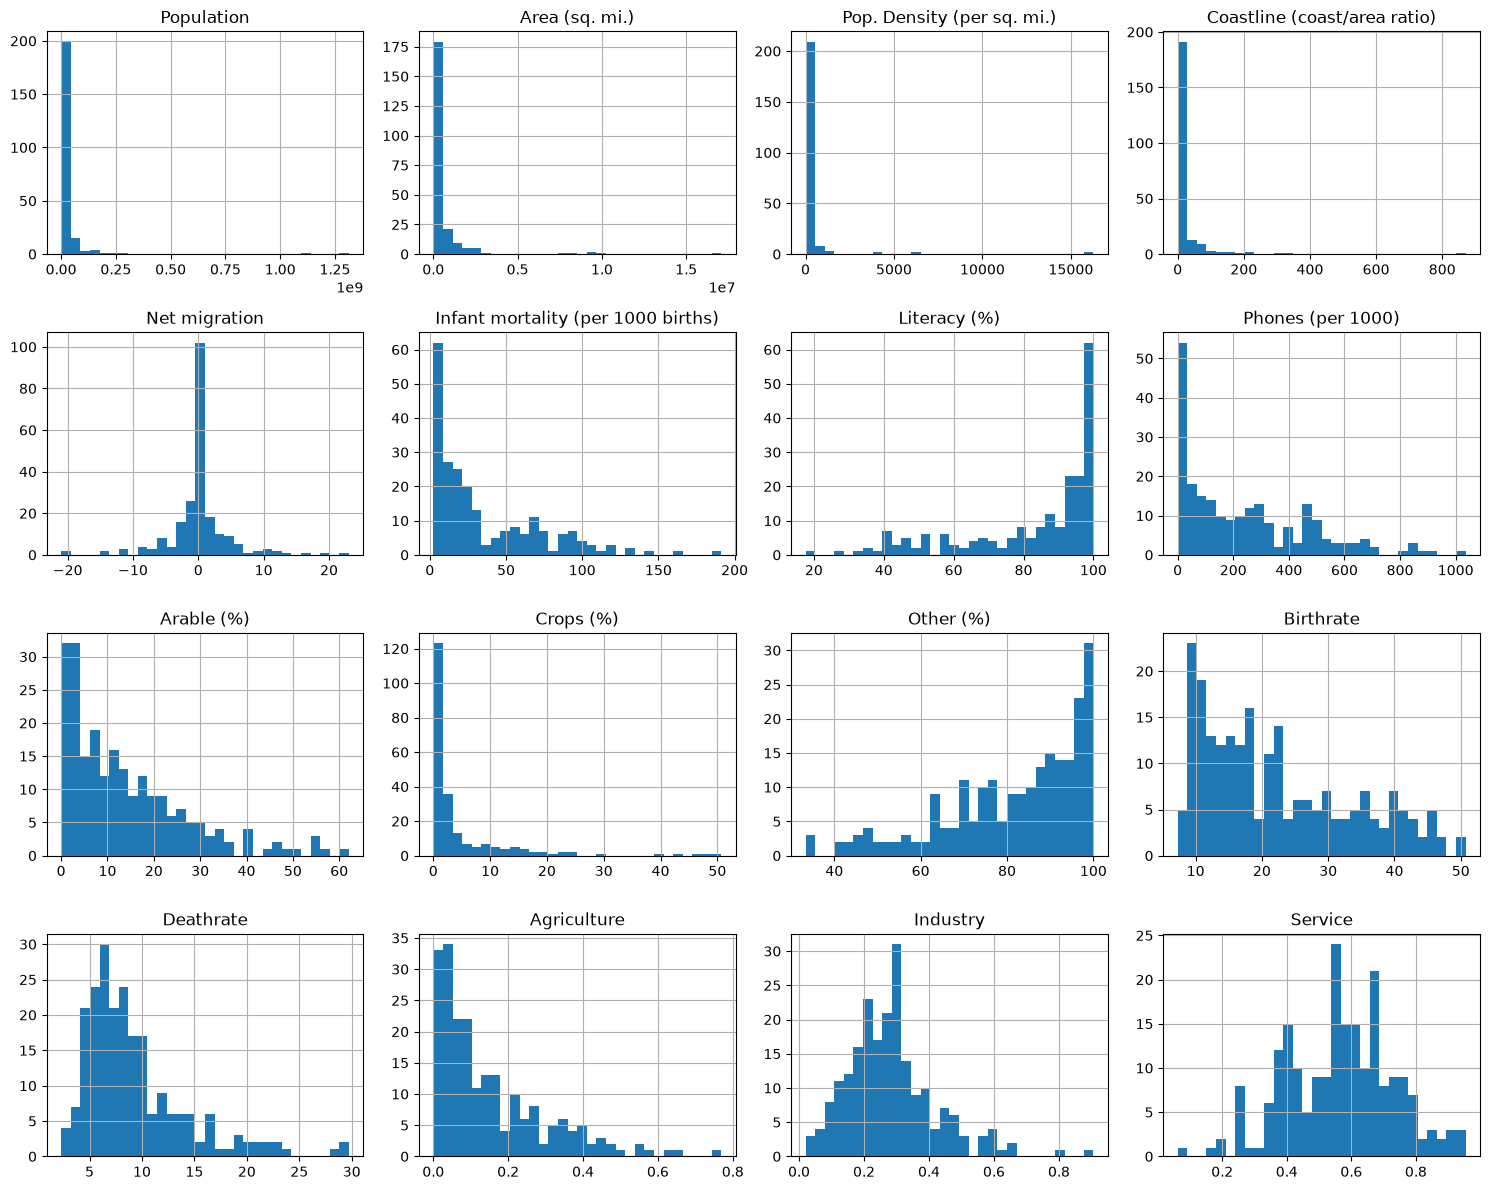

In [147]:
df.hist(
    bins=30,
    figsize=(15, 12)
)

plt.tight_layout()
plt.show()

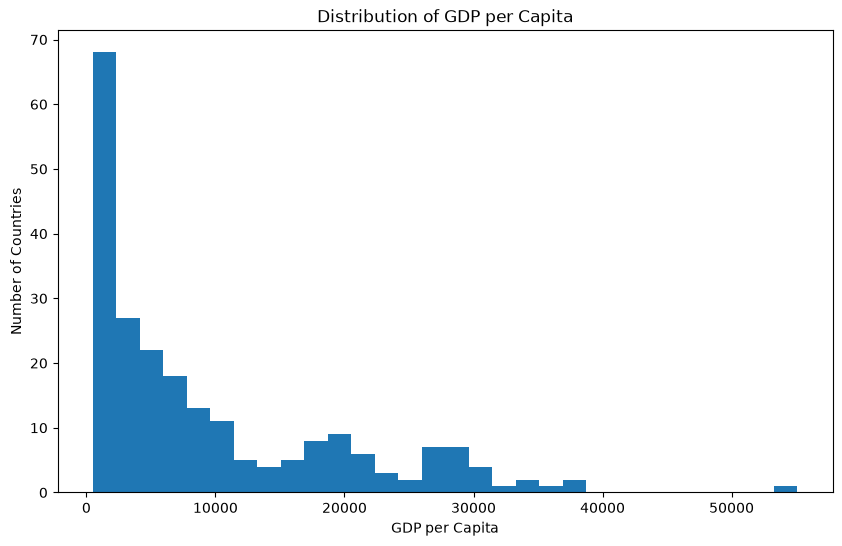

In [148]:
plt.figure(figsize=(10, 6))

plt.hist(
    y,
    bins=30
)

plt.xlabel("GDP per Capita")
plt.ylabel("Number of Countries")
plt.title("Distribution of GDP per Capita")

plt.show()

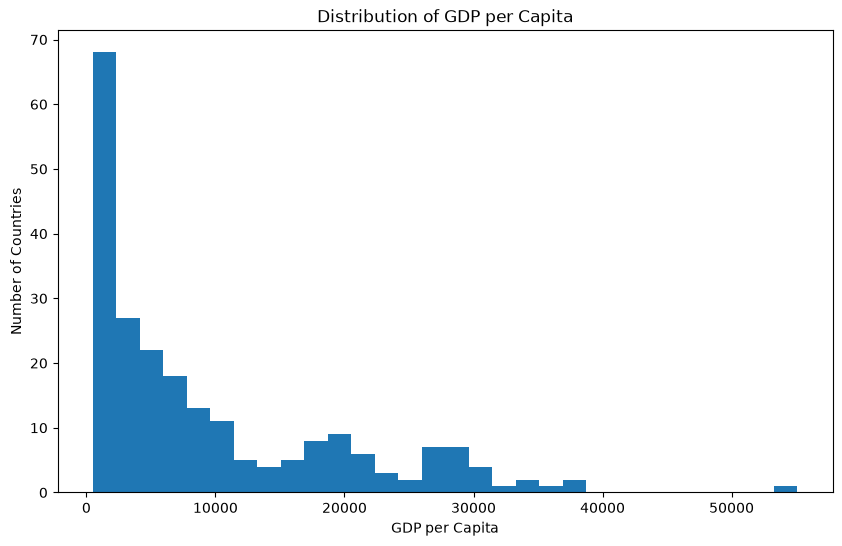

In [149]:
plt.figure(figsize=(10, 6))

plt.hist(
    y,
    bins=30
)

plt.xlabel("GDP per Capita")
plt.ylabel("Number of Countries")
plt.title("Distribution of GDP per Capita")

plt.show()

In [150]:
X_train, X_test, y_train, y_test = train_test_split(
    df,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 180
Testing samples: 46


In [151]:
X_train = X_train.drop("Country", axis=1)
X_test = X_test.drop("Country", axis=1)

In [152]:
correlation_data = X_train.copy()

correlation_data["GDP ($ per capita)"] = y_train

corr_matrix = correlation_data.corr(
    numeric_only=True
)

corr_matrix["GDP ($ per capita)"].sort_values(
    ascending=False
)

GDP ($ per capita)                    1.000000
Phones (per 1000)                     0.842951
Service                               0.533228
Literacy (%)                          0.510723
Net migration                         0.364964
Pop. Density (per sq. mi.)            0.186358
Other (%)                             0.096396
Area (sq. mi.)                        0.092660
Coastline (coast/area ratio)          0.051959
Arable (%)                            0.026258
Industry                             -0.020766
Population                           -0.035535
Deathrate                            -0.192779
Crops (%)                            -0.226359
Agriculture                          -0.584702
Infant mortality (per 1000 births)   -0.599210
Birthrate                            -0.661434
Name: GDP ($ per capita), dtype: float64

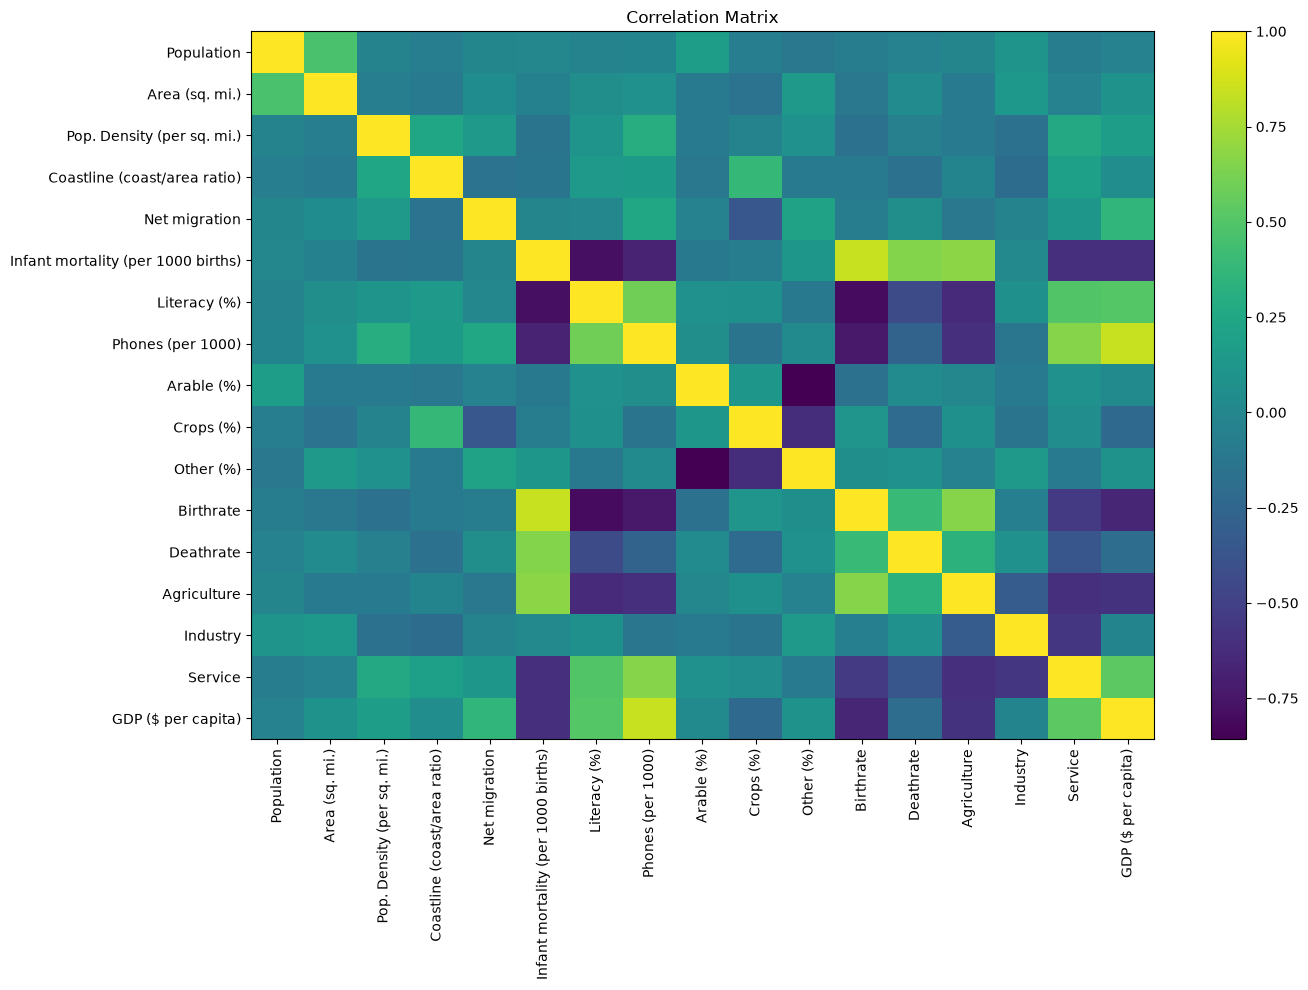

In [153]:
plt.figure(figsize=(14, 10))

plt.imshow(
    corr_matrix,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.show()

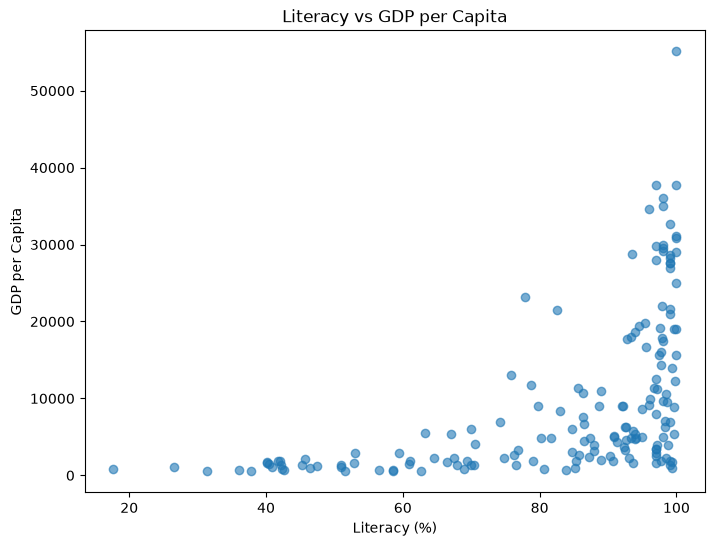

In [154]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train["Literacy (%)"],
    y_train,
    alpha=0.6
)

plt.xlabel("Literacy (%)")
plt.ylabel("GDP per Capita")

plt.title(
    "Literacy vs GDP per Capita"
)

plt.show()

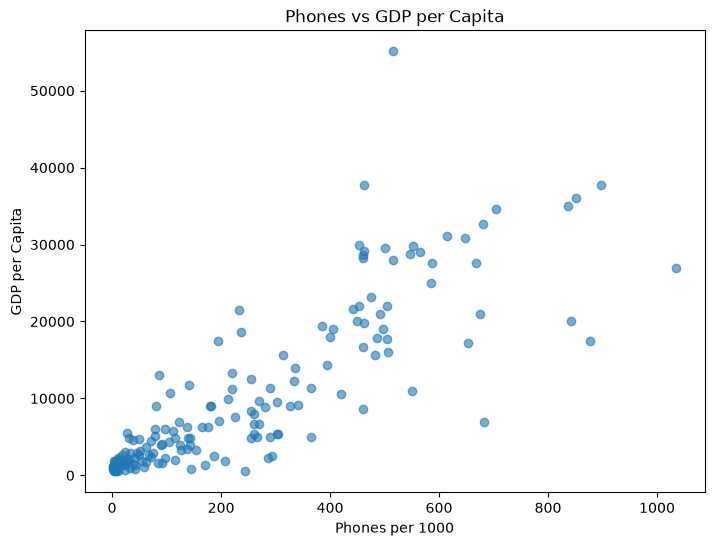

In [155]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train["Phones (per 1000)"],
    y_train,
    alpha=0.6
)

plt.xlabel("Phones per 1000")
plt.ylabel("GDP per Capita")

plt.title(
    "Phones vs GDP per Capita"
)

plt.show()

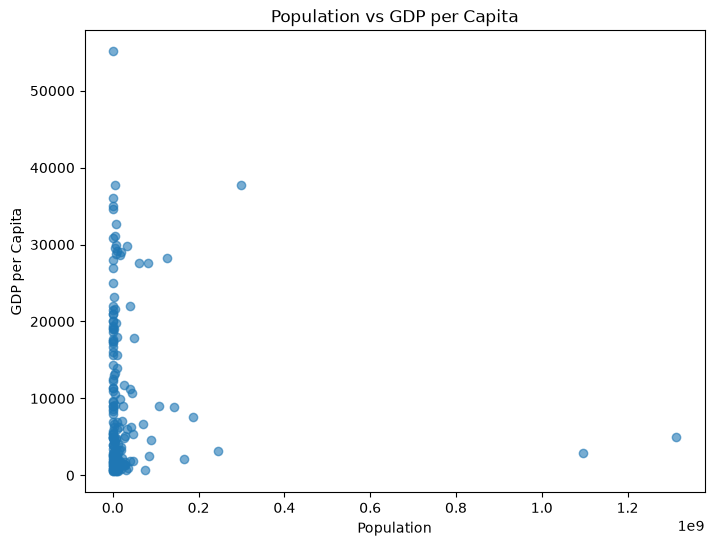

In [156]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train["Population"],
    y_train,
    alpha=0.6
)

plt.xlabel("Population")
plt.ylabel("GDP per Capita")

plt.title(
    "Population vs GDP per Capita"
)

plt.show()

In [157]:
X_train["Natural_Growth_Rate"] = (
    X_train["Birthrate"]
    - X_train["Deathrate"]
)

X_test["Natural_Growth_Rate"] = (
    X_test["Birthrate"]
    - X_test["Deathrate"]
)

In [158]:
X_train["Industry_Service"] = (
    X_train["Industry"]
    + X_train["Service"]
)

X_test["Industry_Service"] = (
    X_test["Industry"]
    + X_test["Service"]
)

In [159]:
X_train["Service_Agriculture_Gap"] = (
    X_train["Service"]
    - X_train["Agriculture"]
)

X_test["Service_Agriculture_Gap"] = (
    X_test["Service"]
    - X_test["Agriculture"]
)

In [160]:
categorical_features = [
    "Region",
    "Climate"
]

print(categorical_features)

['Region', 'Climate']


In [161]:
numeric_features = [
    column
    for column in X_train.columns
    if column not in categorical_features
]

print(numeric_features)

['Population', 'Area (sq. mi.)', 'Pop. Density (per sq. mi.)', 'Coastline (coast/area ratio)', 'Net migration', 'Infant mortality (per 1000 births)', 'Literacy (%)', 'Phones (per 1000)', 'Arable (%)', 'Crops (%)', 'Other (%)', 'Birthrate', 'Deathrate', 'Agriculture', 'Industry', 'Service', 'Natural_Growth_Rate', 'Industry_Service', 'Service_Agriculture_Gap']


In [162]:
numeric_pipeline = Pipeline([
    
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    
    (
        "scaler",
        StandardScaler()
    )
])

In [163]:
categorical_pipeline = Pipeline([
    
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

In [164]:
full_pipeline = ColumnTransformer([
    
    (
        "num",
        numeric_pipeline,
        numeric_features
    ),
    
    (
        "cat",
        categorical_pipeline,
        categorical_features
    )
])

In [165]:
# Convert categorical columns to string type
X_train["Region"] = X_train["Region"].astype("string")
X_test["Region"] = X_test["Region"].astype("string")

X_train["Climate"] = X_train["Climate"].astype("string")
X_test["Climate"] = X_test["Climate"].astype("string")

print("Categorical columns converted to string.")

Categorical columns converted to string.


In [166]:
print("Region data types:")
print(X_train["Region"].map(type).value_counts())

print("\nClimate data types:")
print(X_train["Climate"].map(type).value_counts())

print("\nMissing values:")
print(X_train[["Region", "Climate"]].isna().sum())

Region data types:
Region
<class 'str'>    180
Name: count, dtype: int64

Climate data types:
Climate
<class 'str'>                         163
<class 'pandas.api.typing.NAType'>     17
Name: count, dtype: int64

Missing values:
Region      0
Climate    17
dtype: int64


In [167]:
full_pipeline = ColumnTransformer([
    
    (
        "num",
        numeric_pipeline,
        numeric_features
    ),
    
    (
        "cat",
        categorical_pipeline,
        categorical_features
    )
])

In [168]:
full_pipeline = ColumnTransformer([
    
    (
        "num",
        numeric_pipeline,
        numeric_features
    ),
    
    (
        "cat",
        categorical_pipeline,
        categorical_features
    )
])

In [169]:
numeric_pipeline = Pipeline([
    
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    
    (
        "scaler",
        StandardScaler()
    )
])

In [170]:
full_pipeline = ColumnTransformer([
    
    (
        "num",
        numeric_pipeline,
        numeric_features
    ),
    
    (
        "cat",
        categorical_pipeline,
        categorical_features
    )
])

In [171]:
numeric_features = [
    column
    for column in X_train.columns
    if column not in categorical_features
]

print(numeric_features)

['Population', 'Area (sq. mi.)', 'Pop. Density (per sq. mi.)', 'Coastline (coast/area ratio)', 'Net migration', 'Infant mortality (per 1000 births)', 'Literacy (%)', 'Phones (per 1000)', 'Arable (%)', 'Crops (%)', 'Other (%)', 'Birthrate', 'Deathrate', 'Agriculture', 'Industry', 'Service', 'Natural_Growth_Rate', 'Industry_Service', 'Service_Agriculture_Gap']


In [172]:
for column in categorical_features:
    print("\n", column)
    print(X_train[column].map(type).value_counts())


 Region
Region
<class 'str'>    180
Name: count, dtype: int64

 Climate
Climate
<class 'str'>                         163
<class 'pandas.api.typing.NAType'>     17
Name: count, dtype: int64


In [173]:
# Convert Climate to string
X_train["Climate"] = X_train["Climate"].fillna("Missing").astype(str)
X_test["Climate"] = X_test["Climate"].fillna("Missing").astype(str)

print("Climate converted successfully.")

Climate converted successfully.


In [174]:
print(X_train["Climate"].map(type).value_counts())

Climate
<class 'str'>    180
Name: count, dtype: int64


In [175]:
X_train["Region"] = X_train["Region"].astype(str)
X_test["Region"] = X_test["Region"].astype(str)

In [176]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

In [177]:
full_pipeline = ColumnTransformer([
    (
        "num",
        numeric_pipeline,
        numeric_features
    ),
    (
        "cat",
        categorical_pipeline,
        categorical_features
    )
])

In [178]:
X_train_prepared = full_pipeline.fit_transform(
    X_train
)

print(
    "Prepared training shape:",
    X_train_prepared.shape
)

Prepared training shape: (180, 37)


In [179]:
X_test_prepared = full_pipeline.transform(
    X_test
)

print(
    "Prepared testing shape:",
    X_test_prepared.shape
)

Prepared testing shape: (46, 37)


In [180]:
lin_reg = LinearRegression()

lin_reg.fit(
    X_train_prepared,
    y_train
)

print(
    "Linear Regression trained successfully."
)

Linear Regression trained successfully.


In [181]:
linear_predictions = lin_reg.predict(
    X_train_prepared
)

print("Predictions:")
print(linear_predictions[:5])

print("\nActual GDP:")
print(y_train.iloc[:5].values)

Predictions:
[8835.60611493 3687.85265096 2129.33260243 3902.59463014 8028.37450871]

Actual GDP:
[5800. 1300.  800. 3900. 1100.]


In [182]:
linear_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        linear_predictions
    )
)

linear_mae = mean_absolute_error(
    y_train,
    linear_predictions
)

linear_r2 = r2_score(
    y_train,
    linear_predictions
)

print("Linear Regression")
print("RMSE:", linear_rmse)
print("MAE:", linear_mae)
print("R²:", linear_r2)

Linear Regression
RMSE: 4269.973222963469
MAE: 2884.5905541464326
R²: 0.831592520462431


In [183]:
tree_reg = DecisionTreeRegressor(
    random_state=42
)

tree_reg.fit(
    X_train_prepared,
    y_train
)

print(
    "Decision Tree trained successfully."
)

Decision Tree trained successfully.


In [184]:
tree_predictions = tree_reg.predict(
    X_train_prepared
)

tree_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        tree_predictions
    )
)

tree_mae = mean_absolute_error(
    y_train,
    tree_predictions
)

tree_r2 = r2_score(
    y_train,
    tree_predictions
)

print("Decision Tree")
print("RMSE:", tree_rmse)
print("MAE:", tree_mae)
print("R²:", tree_r2)

Decision Tree
RMSE: 0.0
MAE: 0.0
R²: 1.0


In [185]:
forest_reg = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

forest_reg.fit(
    X_train_prepared,
    y_train
)

print(
    "Random Forest trained successfully."
)

Random Forest trained successfully.


In [186]:
forest_predictions = forest_reg.predict(
    X_train_prepared
)

forest_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        forest_predictions
    )
)

forest_mae = mean_absolute_error(
    y_train,
    forest_predictions
)

forest_r2 = r2_score(
    y_train,
    forest_predictions
)

print("Random Forest")
print("RMSE:", forest_rmse)
print("MAE:", forest_mae)
print("R²:", forest_r2)

Random Forest
RMSE: 1710.7307843920582
MAE: 991.55
R²: 0.9729682343327891


In [187]:
model_results = pd.DataFrame({
    
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    
    "RMSE": [
        linear_rmse,
        tree_rmse,
        forest_rmse
    ],
    
    "MAE": [
        linear_mae,
        tree_mae,
        forest_mae
    ],
    
    "R2": [
        linear_r2,
        tree_r2,
        forest_r2
    ]
})

model_results

,Model,RMSE,MAE,R2
0,Linear Regression,4269.973223,2884.590554,0.831593
1,Decision Tree,0.000000,0.000000,1.000000
2,Random Forest,1710.730784,991.550000,0.972968


In [188]:
linear_cv = cross_val_score(
    lin_reg,
    X_train_prepared,
    y_train,
    scoring="neg_mean_squared_error",
    cv=5
)

tree_cv = cross_val_score(
    tree_reg,
    X_train_prepared,
    y_train,
    scoring="neg_mean_squared_error",
    cv=5
)

forest_cv = cross_val_score(
    forest_reg,
    X_train_prepared,
    y_train,
    scoring="neg_mean_squared_error",
    cv=5
)

In [189]:
linear_cv_rmse = np.sqrt(-linear_cv)

tree_cv_rmse = np.sqrt(-tree_cv)

forest_cv_rmse = np.sqrt(-forest_cv)

In [190]:
cv_results = pd.DataFrame({
    
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    
    "Mean RMSE": [
        linear_cv_rmse.mean(),
        tree_cv_rmse.mean(),
        forest_cv_rmse.mean()
    ],
    
    "Std Dev": [
        linear_cv_rmse.std(),
        tree_cv_rmse.std(),
        forest_cv_rmse.std()
    ]
})

cv_results.sort_values(
    "Mean RMSE"
)

,Model,Mean RMSE,Std Dev
2,Random Forest,4441.734147,1252.608575
0,Linear Regression,5777.270071,1257.343299
1,Decision Tree,7297.169281,1351.660885


In [191]:
param_grid = [
    
    {
        "n_estimators": [50, 100, 200],
        "max_features": [0.5, 0.75, 1.0]
    },
    
    {
        "bootstrap": [False],
        "n_estimators": [50, 100],
        "max_features": [0.5, 0.75, 1.0]
    }
]

In [192]:
grid_search = GridSearchCV(
    RandomForestRegressor(
        random_state=42
    ),
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True
)

In [193]:
grid_search.fit(
    X_train_prepared,
    y_train
)

print(
    "Grid Search completed."
)

Grid Search completed.


In [194]:
print(
    "Best parameters:"
)

print(
    grid_search.best_params_
)

Best parameters:
{'max_features': 0.5, 'n_estimators': 50}


In [195]:
print(
    grid_search.best_estimator_
)

RandomForestRegressor(max_features=0.5, n_estimators=50, random_state=42)


In [196]:
grid_rmse = np.sqrt(
    -grid_search.best_score_
)

print(
    "Best Grid Search RMSE:",
    grid_rmse
)

Best Grid Search RMSE: 4172.24912167686


In [197]:
param_distributions = {
    
    "n_estimators": randint(
        low=50,
        high=300
    ),
    
    "max_features": [
        0.5,
        0.75,
        1.0
    ]
}

In [198]:
random_search = RandomizedSearchCV(
    RandomForestRegressor(
        random_state=42
    ),
    param_distributions=param_distributions,
    n_iter=10,
    cv=5,
    scoring="neg_mean_squared_error",
    random_state=42
)

In [199]:
random_search.fit(
    X_train_prepared,
    y_train
)

print(
    "Randomized Search completed."
)

Randomized Search completed.


In [200]:
print(
    "Best Randomized Search parameters:"
)

print(
    random_search.best_params_
)

Best Randomized Search parameters:
{'max_features': 0.5, 'n_estimators': 149}


In [201]:
random_rmse = np.sqrt(
    -random_search.best_score_
)

print("Grid Search RMSE:", grid_rmse)

print(
    "Randomized Search RMSE:",
    random_rmse
)

Grid Search RMSE: 4172.24912167686
Randomized Search RMSE: 4152.870605885417


In [202]:
if grid_rmse <= random_rmse:

    final_model = grid_search.best_estimator_

    print(
        "Grid Search model selected."
    )

else:

    final_model = random_search.best_estimator_

    print(
        "Randomized Search model selected."
    )

Randomized Search model selected.


In [203]:
feature_importances = (
    final_model.feature_importances_
)

print(feature_importances)

[9.20938134e-03 5.74544024e-03 4.66480167e-03 8.65435135e-03
 5.24241436e-02 2.16843094e-01 1.89926597e-02 3.93039986e-01
 7.01387112e-03 1.49631560e-02 6.34526094e-03 7.28661531e-02
 6.90983943e-03 5.34029292e-02 6.43128480e-03 6.73471777e-03
 2.24697778e-02 5.79429278e-02 1.30654190e-02 1.32981504e-04
 3.49285424e-06 5.00713396e-06 3.68240990e-04 2.02174171e-03
 3.92228570e-04 4.41732115e-05 8.68963555e-04 4.88064844e-05
 1.21075600e-04 1.30816993e-02 1.09471257e-03 1.45674167e-05
 2.91299619e-04 1.80118726e-05 5.46263453e-04 1.16759823e-04
 3.11077957e-03]


In [204]:
feature_names = (
    full_pipeline
    .get_feature_names_out()
)

print(feature_names)

['num__Population' 'num__Area (sq. mi.)' 'num__Pop. Density (per sq. mi.)'
 'num__Coastline (coast/area ratio)' 'num__Net migration'
 'num__Infant mortality (per 1000 births)' 'num__Literacy (%)'
 'num__Phones (per 1000)' 'num__Arable (%)' 'num__Crops (%)'
 'num__Other (%)' 'num__Birthrate' 'num__Deathrate' 'num__Agriculture'
 'num__Industry' 'num__Service' 'num__Natural_Growth_Rate'
 'num__Industry_Service' 'num__Service_Agriculture_Gap'
 'cat__Region_ASIA (EX. NEAR EAST)' 'cat__Region_BALTICS'
 'cat__Region_C.W. OF IND. STATES' 'cat__Region_EASTERN EUROPE'
 'cat__Region_LATIN AMER. & CARIB' 'cat__Region_NEAR EAST'
 'cat__Region_NORTHERN AFRICA' 'cat__Region_NORTHERN AMERICA'
 'cat__Region_OCEANIA' 'cat__Region_SUB-SAHARAN AFRICA'
 'cat__Region_WESTERN EUROPE' 'cat__Climate_1' 'cat__Climate_1,5'
 'cat__Climate_2' 'cat__Climate_2,5' 'cat__Climate_3' 'cat__Climate_4'
 'cat__Climate_Missing']


In [205]:
importance_df = pd.DataFrame({
    
    "Feature": feature_names,
    
    "Importance": feature_importances
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df.head(20)

,Feature,Importance
7,num__Phones (per 1000),0.393040
5,num__Infant mortality (per 1000 births),0.216843
11,num__Birthrate,0.072866
17,num__Industry_Service,0.057943
13,num__Agriculture,0.053403
4,num__Net migration,0.052424
16,num__Natural_Growth_Rate,0.022470
6,num__Literacy (%),0.018993
9,num__Crops (%),0.014963
29,cat__Region_WESTERN EUROPE,0.013082


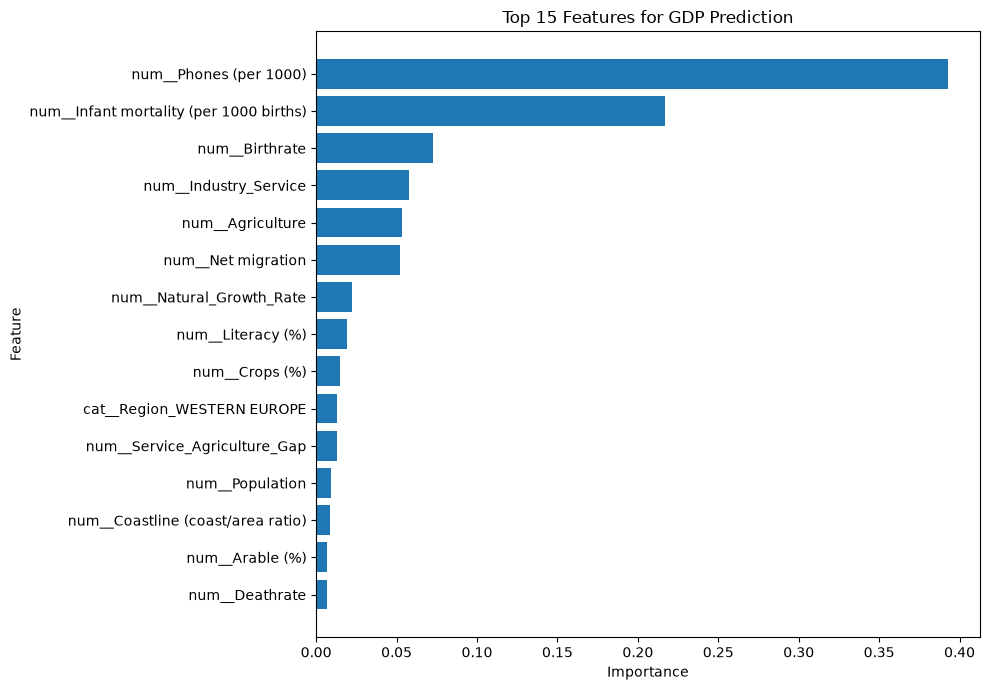

In [206]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Top 15 Features for GDP Prediction"
)

plt.tight_layout()

plt.show()

In [207]:
train_predictions = final_model.predict(
    X_train_prepared
)

errors = (
    y_train
    - train_predictions
)

error_rmse = np.sqrt(
    np.mean(errors ** 2)
)

print(
    "Training RMSE:",
    error_rmse
)

Training RMSE: 1638.1824227710458


In [208]:
error_table = pd.DataFrame({
    
    "Actual GDP": y_train.values,
    
    "Predicted GDP": train_predictions,
    
    "Error": errors.values
})

error_table["Absolute Error"] = (
    error_table["Error"].abs()
)

error_table.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

,Actual GDP,Predicted GDP,Error,Absolute Error
170,55100.0,44075.167785,11024.832215,11024.832215
140,6900.0,13193.959732,-6293.959732,6293.959732
74,8600.0,13637.583893,-5037.583893,5037.583893
139,10600.0,14969.127517,-4369.127517,4369.127517
80,19000.0,23000.671141,-4000.671141,4000.671141
67,36000.0,32116.107383,3883.892617,3883.892617
163,21000.0,24704.697987,-3704.697987,3704.697987
167,600.0,4072.483221,-3472.483221,3472.483221
38,2900.0,6252.348993,-3352.348993,3352.348993
79,37800.0,34526.174497,3273.825503,3273.825503


In [209]:
final_predictions = final_model.predict(
    X_test_prepared
)

In [210]:
final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_predictions
    )
)

print(
    "Final Test RMSE:",
    final_rmse
)

Final Test RMSE: 2981.353848509122


In [211]:
final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

print(
    "Final Test MAE:",
    final_mae
)

Final Test MAE: 2281.237233732127


In [212]:
final_r2 = r2_score(
    y_test,
    final_predictions
)

print(
    "Final Test R²:",
    final_r2
)

Final Test R²: 0.8735624324721649


In [213]:
final_results = pd.DataFrame({
    
    "Metric": [
        "RMSE",
        "MAE",
        "R²"
    ],
    
    "Value": [
        final_rmse,
        final_mae,
        final_r2
    ]
})

final_results

,Metric,Value
0,RMSE,2981.353849
1,MAE,2281.237234
2,R²,0.873562


In [214]:
prediction_comparison = pd.DataFrame({
    
    "Actual GDP": y_test.values,
    
    "Predicted GDP": final_predictions
})

prediction_comparison["Error"] = (
    prediction_comparison["Actual GDP"]
    - prediction_comparison["Predicted GDP"]
)

prediction_comparison.head(20)

,Actual GDP,Predicted GDP,Error
0,3500.0,4204.697987,-704.697987
1,23700.0,26587.919463,-2887.919463
2,11400.0,10940.268456,459.731544
3,5800.0,2236.241611,3563.758389
4,15000.0,9436.912752,5563.087248
5,12800.0,7812.080537,4987.919463
6,7800.0,11746.979866,-3946.979866
7,2100.0,1165.771812,934.228188
8,1200.0,2016.107383,-816.107383
9,2900.0,5924.832215,-3024.832215


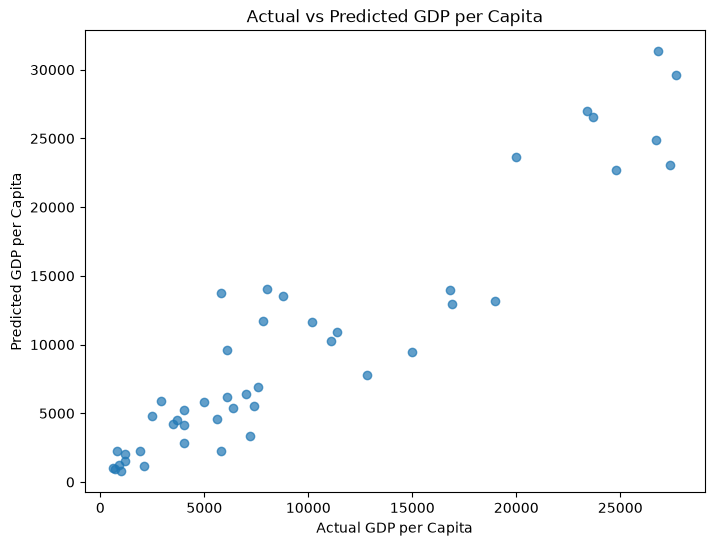

In [215]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.7
)

plt.xlabel("Actual GDP per Capita")
plt.ylabel("Predicted GDP per Capita")

plt.title(
    "Actual vs Predicted GDP per Capita"
)

plt.show()

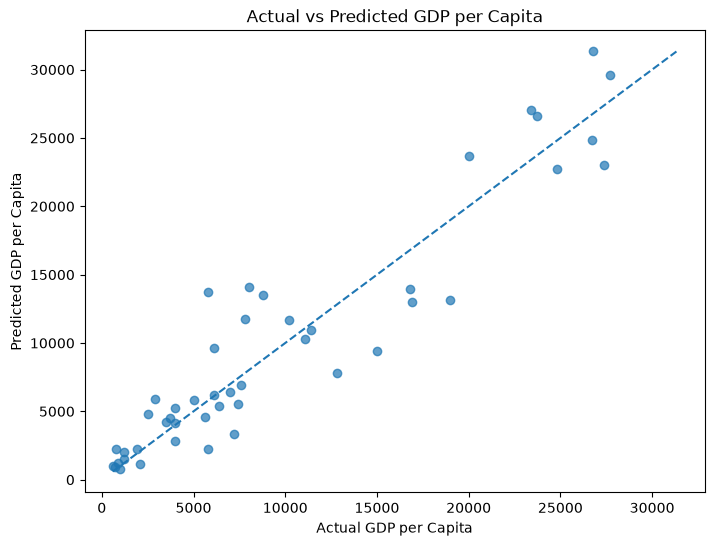

In [216]:
minimum = min(
    y_test.min(),
    final_predictions.min()
)

maximum = max(
    y_test.max(),
    final_predictions.max()
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.7
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual GDP per Capita")
plt.ylabel("Predicted GDP per Capita")

plt.title(
    "Actual vs Predicted GDP per Capita"
)

plt.show()

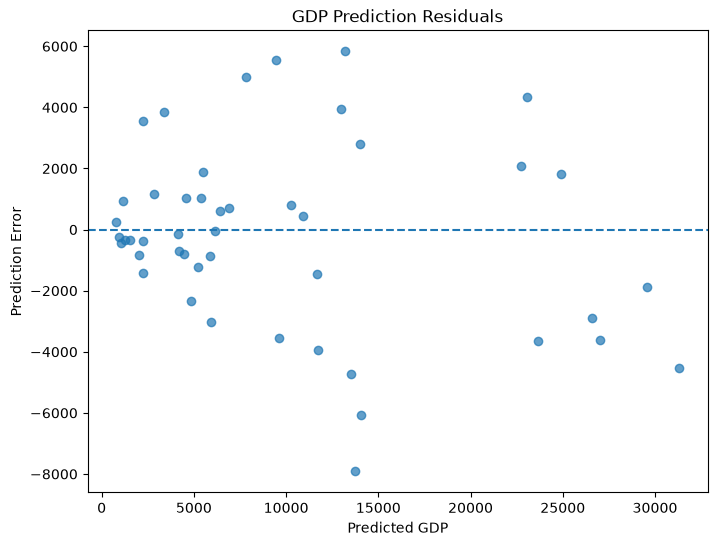

In [217]:
residuals = (
    y_test.values
    - final_predictions
)

plt.figure(figsize=(8, 6))

plt.scatter(
    final_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted GDP")
plt.ylabel("Prediction Error")

plt.title(
    "GDP Prediction Residuals"
)

plt.show()

In [218]:
test_results = X_test.copy()

test_results["Actual GDP"] = y_test.values

test_results["Predicted GDP"] = (
    final_predictions
)

test_results["Absolute Error"] = (
    abs(
        test_results["Actual GDP"]
        - test_results["Predicted GDP"]
    )
)

test_results.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

,Region,Population,Area (sq. mi.),Pop. Density (per sq. mi.),Coastline (coast/area ratio),Net migration,Infant mortality (per 1000 births),Literacy (%),Phones (per 1000),Arable (%),...,Deathrate,Agriculture,Industry,Service,Natural_Growth_Rate,Industry_Service,Service_Agriculture_Gap,Actual GDP,Predicted GDP,Absolute Error
167,SUB-SAHARAN AFRICA,787584,2517,312.9,8.22,0.00,7.78,88.9,380.9,13.60,...,5.49,0.080,0.190,0.730,13.41,0.920,0.650,5800.0,13718.120805,7918.120805
82,LATIN AMER. & CARIB,452776,1780,254.4,17.19,-0.15,8.60,90.0,463.8,11.24,...,6.09,0.150,0.170,0.680,8.96,0.850,0.530,8000.0,14063.087248,6063.087248
111,NEAR EAST,2418393,17820,135.7,2.80,14.18,9.95,83.5,211.0,0.73,...,2.41,0.004,0.479,0.516,19.53,0.995,0.512,19000.0,13170.469799,5829.530201
148,OCEANIA,219246,19060,11.5,11.83,0.00,7.72,91.0,252.2,0.38,...,5.69,0.150,0.088,0.762,12.42,0.850,0.612,15000.0,9436.912752,5563.087248
215,LATIN AMER. & CARIB,3431932,176220,19.5,0.37,-0.32,11.95,98.0,291.4,7.43,...,9.05,0.093,0.311,0.596,4.86,0.907,0.503,12800.0,7812.080537,4987.919463
172,LATIN AMER. & CARIB,39129,261,149.9,51.72,-7.11,14.49,97.0,638.9,19.44,...,8.33,0.035,0.258,0.707,9.69,0.965,0.672,8800.0,13514.093960,4714.093960
195,WESTERN EUROPE,9016596,449964,20.0,0.72,1.67,2.77,99.0,715.0,6.54,...,10.31,0.011,0.282,0.707,-0.04,0.989,0.696,26800.0,31325.503356,4525.503356
68,WESTERN EUROPE,5231372,338145,15.5,0.37,0.95,3.57,100.0,405.3,7.19,...,9.86,0.028,0.295,0.676,0.59,0.971,0.648,27400.0,23044.295302,4355.704698
182,SUB-SAHARAN AFRICA,81541,455,179.2,107.91,-5.69,15.53,58.0,262.4,2.22,...,6.29,0.032,0.304,0.665,9.74,0.969,0.633,7800.0,11746.979866,3946.979866
15,NEAR EAST,698585,665,1050.5,24.21,1.05,17.27,89.1,281.3,2.82,...,4.14,0.005,0.387,0.608,13.66,0.995,0.603,16900.0,12965.771812,3934.228188


In [219]:
joblib.dump(
    final_model,
    "GDP_prediction_model.pkl"
)

print(
    "Final GDP prediction model saved."
)

Final GDP prediction model saved.


In [220]:
joblib.dump(
    full_pipeline,
    "GDP_preprocessing_pipeline.pkl"
)

print(
    "Preprocessing pipeline saved."
)

Preprocessing pipeline saved.


In [221]:
loaded_model = joblib.load(
    "GDP_prediction_model.pkl"
)

loaded_pipeline = joblib.load(
    "GDP_preprocessing_pipeline.pkl"
)

print("Model and pipeline loaded successfully.")

Model and pipeline loaded successfully.


In [222]:
loaded_test_data = loaded_pipeline.transform(
    X_test
)

loaded_predictions = loaded_model.predict(
    loaded_test_data
)

print(
    loaded_predictions[:10]
)

[ 4204.69798658 26587.91946309 10940.26845638  2236.24161074
  9436.91275168  7812.08053691 11746.97986577  1165.77181208
  2016.10738255  5924.83221477]


In [223]:
comparison = pd.DataFrame({
    "Actual GDP": y_test.values,
    "Predicted GDP": loaded_predictions
})

comparison["Error"] = (
    comparison["Actual GDP"]
    - comparison["Predicted GDP"]
)

comparison["Absolute Error"] = (
    comparison["Error"].abs()
)

comparison.head(20)

,Actual GDP,Predicted GDP,Error,Absolute Error
0,3500.0,4204.697987,-704.697987,704.697987
1,23700.0,26587.919463,-2887.919463,2887.919463
2,11400.0,10940.268456,459.731544,459.731544
3,5800.0,2236.241611,3563.758389,3563.758389
4,15000.0,9436.912752,5563.087248,5563.087248
5,12800.0,7812.080537,4987.919463,4987.919463
6,7800.0,11746.979866,-3946.979866,3946.979866
7,2100.0,1165.771812,934.228188,934.228188
8,1200.0,2016.107383,-816.107383,816.107383
9,2900.0,5924.832215,-3024.832215,3024.832215


In [224]:
final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        loaded_predictions
    )
)

print("Final Test RMSE:", final_rmse)

Final Test RMSE: 2981.353848509122


In [225]:
final_mae = mean_absolute_error(
    y_test,
    loaded_predictions
)

print("Final Test MAE:", final_mae)

Final Test MAE: 2281.237233732127


In [226]:
final_r2 = r2_score(
    y_test,
    loaded_predictions
)

print("Final Test R²:", final_r2)

Final Test R²: 0.8735624324721649


In [227]:
final_results = pd.DataFrame({
    "Metric": [
        "RMSE",
        "MAE",
        "R²"
    ],
    
    "Test Score": [
        final_rmse,
        final_mae,
        final_r2
    ]
})

final_results

,Metric,Test Score
0,RMSE,2981.353849
1,MAE,2281.237234
2,R²,0.873562


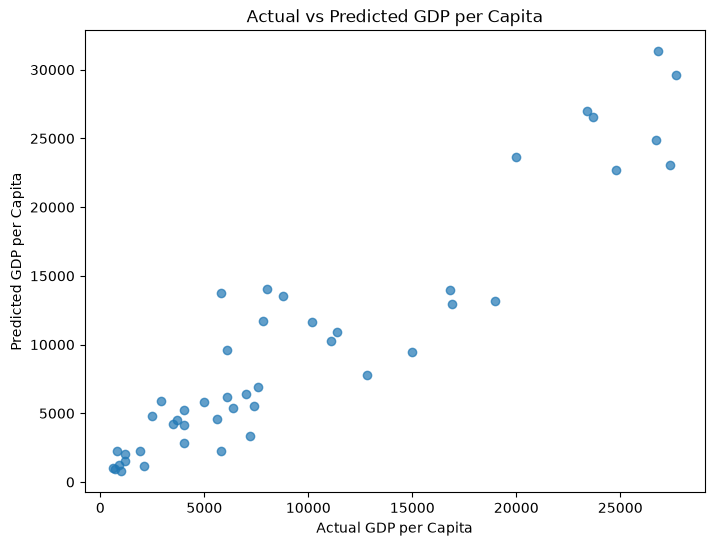

In [228]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    loaded_predictions,
    alpha=0.7
)

plt.xlabel("Actual GDP per Capita")
plt.ylabel("Predicted GDP per Capita")

plt.title(
    "Actual vs Predicted GDP per Capita"
)

plt.show()

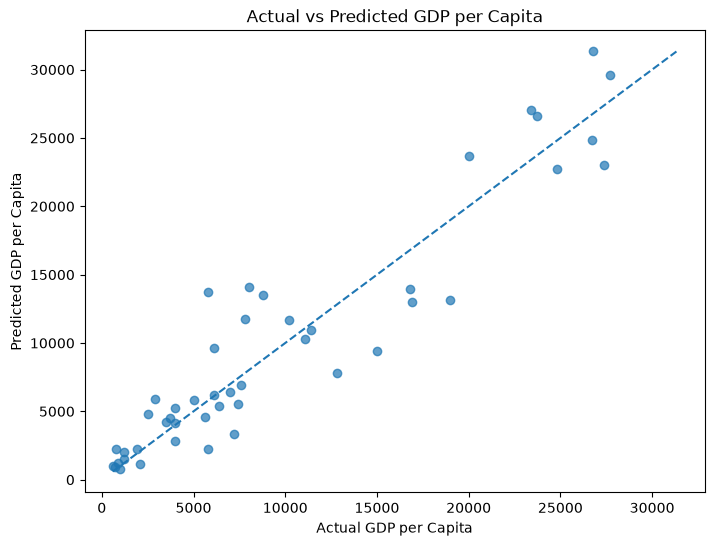

In [229]:
minimum = min(
    y_test.min(),
    loaded_predictions.min()
)

maximum = max(
    y_test.max(),
    loaded_predictions.max()
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    loaded_predictions,
    alpha=0.7
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual GDP per Capita")
plt.ylabel("Predicted GDP per Capita")

plt.title(
    "Actual vs Predicted GDP per Capita"
)

plt.show()

In [230]:
comparison.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

,Actual GDP,Predicted GDP,Error,Absolute Error
22,5800.0,13718.120805,-7918.120805,7918.120805
25,8000.0,14063.087248,-6063.087248,6063.087248
38,19000.0,13170.469799,5829.530201,5829.530201
4,15000.0,9436.912752,5563.087248,5563.087248
5,12800.0,7812.080537,4987.919463,4987.919463
27,8800.0,13514.093960,-4714.093960,4714.093960
36,26800.0,31325.503356,-4525.503356,4525.503356
10,27400.0,23044.295302,4355.704698,4355.704698
6,7800.0,11746.979866,-3946.979866,3946.979866
11,16900.0,12965.771812,3934.228188,3934.228188


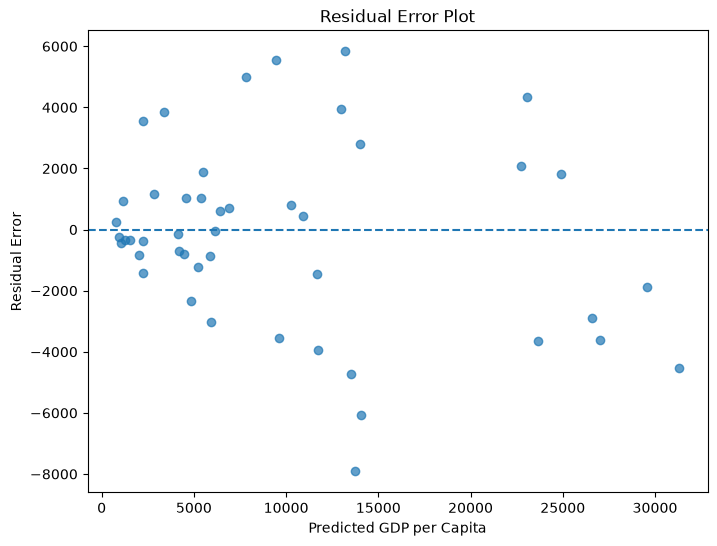

In [231]:
residuals = (
    y_test.values
    - loaded_predictions
)

plt.figure(figsize=(8, 6))

plt.scatter(
    loaded_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted GDP per Capita")
plt.ylabel("Residual Error")

plt.title(
    "Residual Error Plot"
)

plt.show()

In [232]:
model_comparison = pd.DataFrame({
    
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    
    "RMSE": [
        linear_rmse,
        tree_rmse,
        forest_rmse
    ],
    
    "MAE": [
        linear_mae,
        tree_mae,
        forest_mae
    ],
    
    "R2": [
        linear_r2,
        tree_r2,
        forest_r2
    ]
})

model_comparison

,Model,RMSE,MAE,R2
0,Linear Regression,4269.973223,2884.590554,0.831593
1,Decision Tree,0.000000,0.000000,1.000000
2,Random Forest,1710.730784,991.550000,0.972968


In [233]:
cv_results

,Model,Mean RMSE,Std Dev
0,Linear Regression,5777.270071,1257.343299
1,Decision Tree,7297.169281,1351.660885
2,Random Forest,4441.734147,1252.608575


In [234]:
cv_results.sort_values(
    "Mean RMSE"
)

,Model,Mean RMSE,Std Dev
2,Random Forest,4441.734147,1252.608575
0,Linear Regression,5777.270071,1257.343299
1,Decision Tree,7297.169281,1351.660885


In [235]:
print("Best model:")
print(loaded_model)

Best model:
RandomForestRegressor(max_features=0.5, n_estimators=149, random_state=42)


In [236]:
print("Best parameters:")
print(random_search.best_params_)

Best parameters:
{'max_features': 0.5, 'n_estimators': 149}


In [237]:
feature_importances = loaded_model.feature_importances_

feature_names = full_pipeline.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
7,num__Phones (per 1000),0.393040
5,num__Infant mortality (per 1000 births),0.216843
11,num__Birthrate,0.072866
17,num__Industry_Service,0.057943
13,num__Agriculture,0.053403
4,num__Net migration,0.052424
16,num__Natural_Growth_Rate,0.022470
6,num__Literacy (%),0.018993
9,num__Crops (%),0.014963
29,cat__Region_WESTERN EUROPE,0.013082


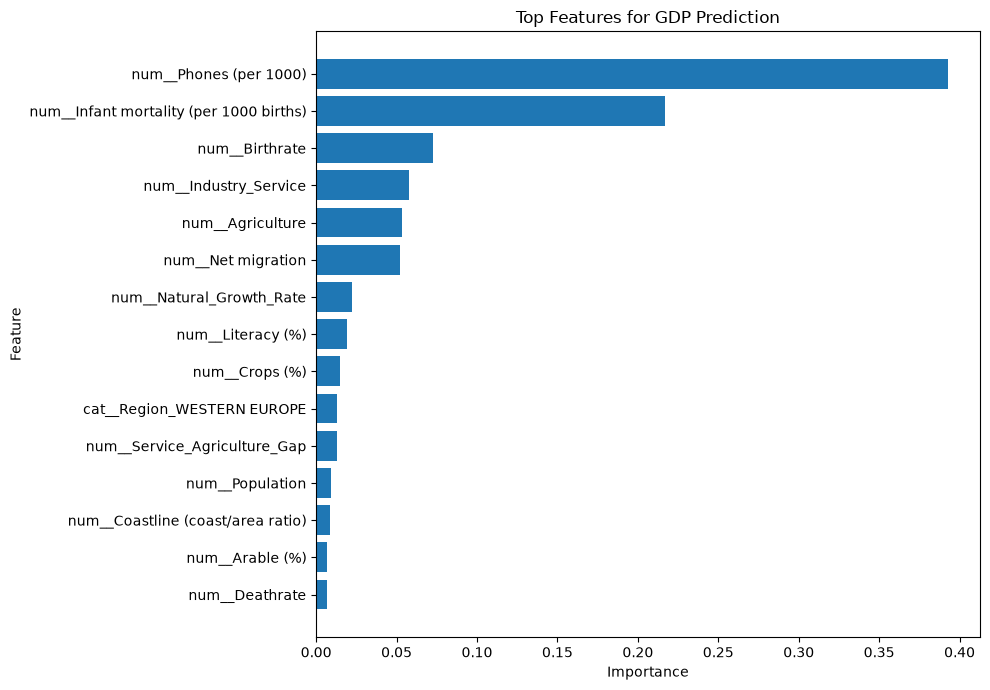

In [238]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Top Features for GDP Prediction"
)

plt.tight_layout()

plt.show()

In [239]:
comparison = pd.DataFrame({
    "Actual GDP": y_test.values,
    "Predicted GDP": loaded_predictions
})

comparison["Error"] = (
    comparison["Actual GDP"]
    - comparison["Predicted GDP"]
)

comparison["Absolute Error"] = (
    comparison["Error"].abs()
)

comparison.head(20)

,Actual GDP,Predicted GDP,Error,Absolute Error
0,3500.0,4204.697987,-704.697987,704.697987
1,23700.0,26587.919463,-2887.919463,2887.919463
2,11400.0,10940.268456,459.731544,459.731544
3,5800.0,2236.241611,3563.758389,3563.758389
4,15000.0,9436.912752,5563.087248,5563.087248
5,12800.0,7812.080537,4987.919463,4987.919463
6,7800.0,11746.979866,-3946.979866,3946.979866
7,2100.0,1165.771812,934.228188,934.228188
8,1200.0,2016.107383,-816.107383,816.107383
9,2900.0,5924.832215,-3024.832215,3024.832215


In [240]:
final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        loaded_predictions
    )
)

final_mae = mean_absolute_error(
    y_test,
    loaded_predictions
)

final_r2 = r2_score(
    y_test,
    loaded_predictions
)

print("========== FINAL TEST RESULTS ==========")
print("RMSE:", final_rmse)
print("MAE :", final_mae)
print("R²  :", final_r2)

========== FINAL TEST RESULTS ==========
RMSE: 2981.353848509122
MAE : 2281.237233732127
R²  : 0.8735624324721649


In [241]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse,
        forest_rmse
    ],
    "MAE": [
        linear_mae,
        tree_mae,
        forest_mae
    ],
    "R2": [
        linear_r2,
        tree_r2,
        forest_r2
    ]
})

model_comparison

,Model,RMSE,MAE,R2
0,Linear Regression,4269.973223,2884.590554,0.831593
1,Decision Tree,0.000000,0.000000,1.000000
2,Random Forest,1710.730784,991.550000,0.972968


In [242]:
cv_results.sort_values("Mean RMSE")

,Model,Mean RMSE,Std Dev
2,Random Forest,4441.734147,1252.608575
0,Linear Regression,5777.270071,1257.343299
1,Decision Tree,7297.169281,1351.660885
